# TinyML thermal and power risk: training walkthrough

This notebook shows every step from the captured board data to the C code that runs on the STM32 Nucleo-F446RE.
It uses the same functions as `scripts/train_model.py` and `scripts/compare_models.py`, so the numbers here are the numbers in the firmware.

**Steps**
1. Load the 3 h capture and look at it
2. Features: the 7 inputs computed every second
3. Labels: what the model must predict, 15 s ahead
4. Train / validation / test split (chronological)
5. Compare 6 candidate models, choose on validation only
6. Train the chosen model, export it to C and TFLite
7. Results: ML vs the slope rule

Run with **Kernel → Restart & Run All** (about 10–12 minutes). Needs: `pip install tensorflow scikit-learn pandas numpy matplotlib jupyter`.

In [1]:
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent            # the project folder (this notebook is in notebooks/)
sys.path.insert(0, str(ROOT / "scripts"))
import train_model as tm            # same data pipeline as the command-line scripts

DATA = [str(ROOT / "data" / "auto1.csv")]
H = 15                              # prediction horizon, seconds
plt.rcParams["figure.figsize"] = (11, 4)

## 1. The data

Captured with `capture_data.py` while the board ran `MODE AUTO`: a random workload schedule (long heat-ups, cool-downs, short bursts), one `DATA` row per second.
Rows from `MODE RUN` are excluded, because there the reaction throttles the workload and hides the board's natural behaviour.

In [2]:
segments = tm.load_segments(DATA, include_run=False)
df = pd.concat(segments, ignore_index=True)
print(f"{len(df)} rows = {len(df)/3600:.1f} h in {len(segments)} segment(s)")
df[["power_mw", "temp_die_c", "temp_rise_c", "temp_ambient_c", "workload_eff"]].describe().round(2)

  /home/claude/bat-daemon/tinyml_thermal_power_mgmt_project/data/auto1.csv: 10800 rows
10800 rows = 3.0 h in 1 segment(s)


,power_mw,temp_die_c,temp_rise_c,temp_ambient_c,workload_eff
count,10800.00,10800.00,10800.00,10800.00,10800.00
mean,166.71,37.89,7.24,30.02,1.83
std,72.01,3.28,3.27,0.33,1.30
min,67.70,32.22,1.60,28.21,0.00
25%,70.00,34.43,3.77,29.82,0.00
50%,176.24,38.52,7.87,30.06,2.00
75%,233.62,41.09,10.43,30.14,3.00
max,236.75,41.96,11.22,31.99,3.00


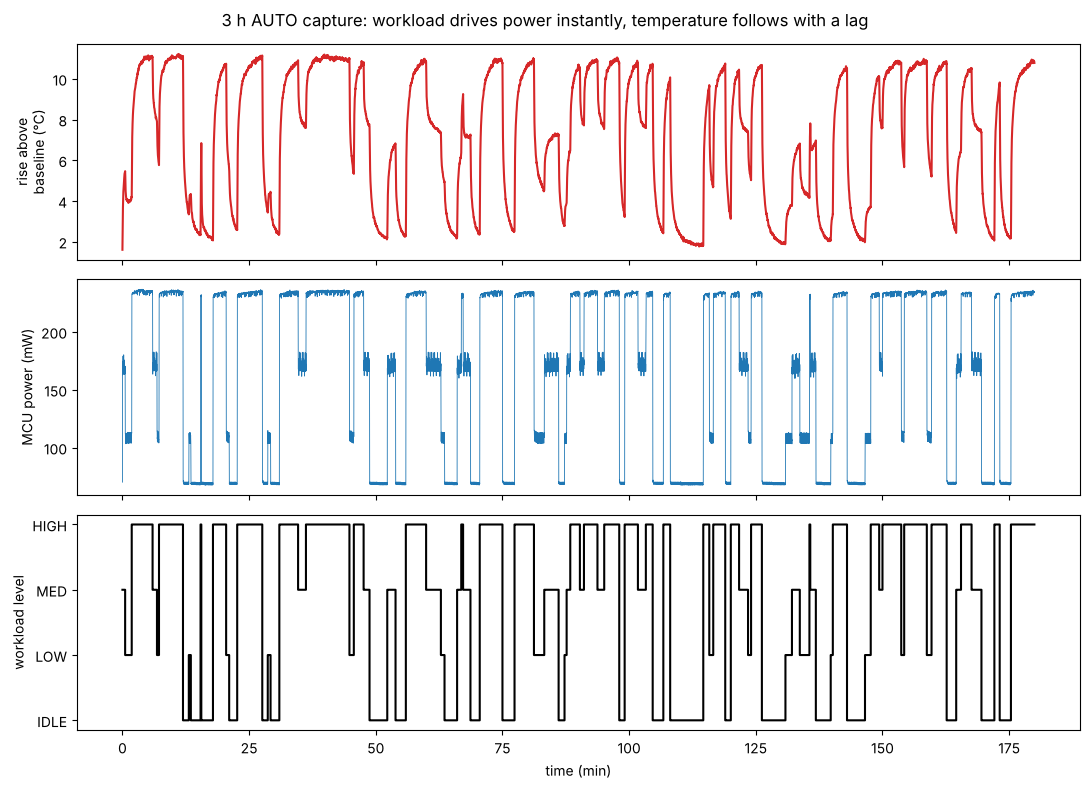

In [3]:
seg = segments[0]
t_min = (seg["timestamp_ms"] - seg["timestamp_ms"].iloc[0]) / 60000
fig, ax = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
ax[0].plot(t_min, seg["temp_rise_c"], color="tab:red"); ax[0].set_ylabel("rise above\nbaseline (°C)")
ax[1].plot(t_min, seg["power_mw"], color="tab:blue", lw=0.6); ax[1].set_ylabel("MCU power (mW)")
ax[2].step(t_min, seg["workload_eff"], where="post", color="black"); ax[2].set_ylabel("workload level")
ax[2].set_yticks([0, 1, 2, 3]); ax[2].set_yticklabels(["IDLE", "LOW", "MED", "HIGH"])
ax[2].set_xlabel("time (min)")
fig.suptitle("3 h AUTO capture: workload drives power instantly, temperature follows with a lag")
fig.tight_layout()

Power jumps the moment the workload changes, but the temperature takes about 1–2 minutes to settle. That lag is why a **prediction** is useful: by the time the temperature crosses a limit, the cause (power) has been visible for a while.

workload_eff
IDLE     68.5
LOW     111.8
MED     170.7
HIGH    233.6
Name: power_mw, dtype: float64

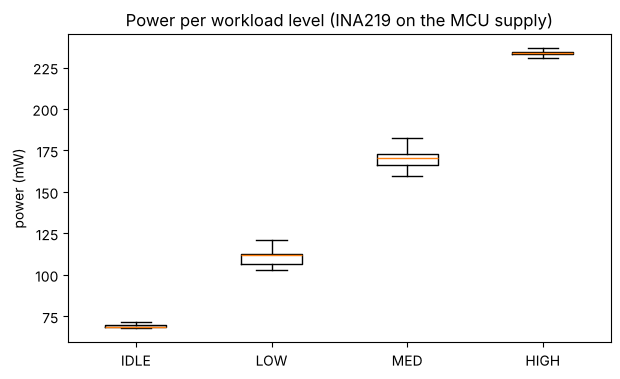

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
levels = ["IDLE", "LOW", "MED", "HIGH"]
ax.boxplot([df.loc[df.workload_eff == k, "power_mw"] for k in range(4)], showfliers=False)
ax.set_xticks([1, 2, 3, 4], levels); ax.set_ylabel("power (mW)")
ax.set_title("Power per workload level (INA219 on the MCU supply)")
df.groupby("workload_eff")["power_mw"].median().rename(index=dict(enumerate(levels))).round(1)

## 2. Features

Every second the firmware computes 7 numbers from the last 10 s (`feature_extraction.c`); `compute_features()` below is the same maths in Python (they agree to ~1e-5).
The temperature is used as a **rise above the idle baseline** measured at boot, so the model does not depend on the room temperature.

In [5]:
X_all = tm.compute_features(seg)
pd.DataFrame(X_all[tm.FEATURE_WINDOW:], columns=tm.FEATURE_NAMES).describe().round(3)

,temp_rise,temp_slope10,temp_slope3,power_now,power_avg10,power_slope10,workload
count,10790.000,10790.000,10790.000,10790.000,10790.000,10790.000,10790.000
mean,7.244,0.001,0.001,166.722,166.694,0.006,1.826
std,3.273,0.087,0.104,72.032,70.834,3.392,1.300
min,1.760,-0.516,-0.833,67.700,68.280,-18.482,0.000
25%,3.780,-0.012,-0.017,70.000,69.233,-0.066,0.000
50%,7.880,0.000,0.000,176.470,171.632,0.000,2.000
75%,10.430,0.014,0.020,233.620,233.501,0.074,3.000
max,11.220,0.509,0.813,236.750,236.168,18.298,3.000


## 3. Labels: what really happened in the next 15 s

For each second *t*:
- **temperature risk** = class of the **highest** rise during *t+1 … t+15 s*
- **power risk** = class of the **mean** power during *t+1 … t+15 s*

The limits come from the **training part of the data only** (so the test part has no say in its own labels): temperature caution / critical = 50 % / 80 % of the 98th-percentile rise; power at 55 % / 85 % of the 5th–98th percentile range.

98th-percentile rise (training part) 11.08 C, power range 68-235 mW
{'caution_rise': 5.5, 'critical_rise': 8.9, 'caution_power': 160.1, 'critical_power': 210.3}


,temperature,power
NORMAL,3345,4098
CAUTION,2323,1709
CRITICAL,5108,4969


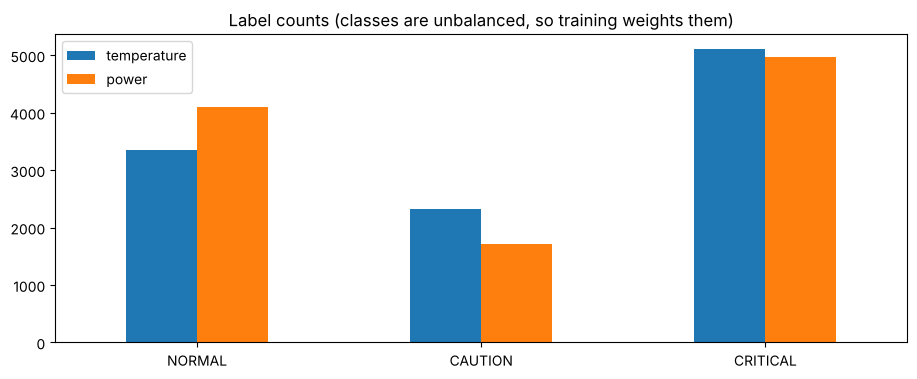

In [6]:
thr, rise_hi, p_lo, p_hi = tm.thresholds_from_train(segments, H)   # training rows only
print(f"98th-percentile rise (training part) {rise_hi:.2f} C, power range {p_lo:.0f}-{p_hi:.0f} mW")
print(thr)

fut_rise, fut_pow = tm.future_targets(seg, H)
valid = np.arange(tm.FEATURE_WINDOW - 1, len(seg) - H)
y_t = tm.classify(fut_rise[valid], thr["caution_rise"], thr["critical_rise"])
y_p = tm.classify(fut_pow[valid], thr["caution_power"], thr["critical_power"])
counts = pd.DataFrame({"temperature": np.bincount(y_t, minlength=3), "power": np.bincount(y_p, minlength=3)},
                      index=tm.CLASS_NAMES)
counts.plot.bar(rot=0, title="Label counts (classes are unbalanced, so training weights them)"); counts

## 4. Train / validation / test split

**Chronological**, not random. A random split would leak, because neighbouring seconds are almost identical and the test score would look better than it really is.
- **fit**: the first ~64 % of the recording, used to train
- **validation**: the next ~11 % (the last 15 % of the training part), used for early stopping, picking the seed and **choosing the model**
- **test**: the last 25 % (about 45 min), never used for any decision, only to report the final numbers

fit rows 6870, validation rows 1212, test rows 2694


Text(0.5, 1.0, 'Chronological split')

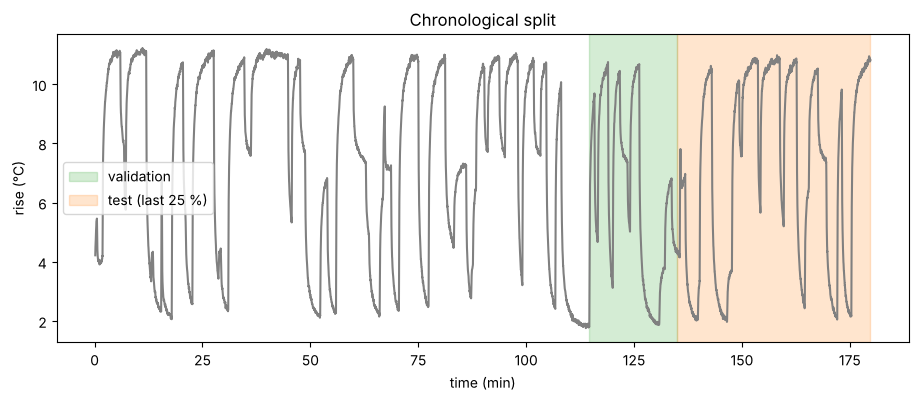

In [7]:
cut = int(len(valid) * tm.TRAIN_FRACTION)
nv = int(cut * 0.15)
print(f"fit rows {cut - nv}, validation rows {nv}, test rows {len(valid) - cut}")
fig, ax = plt.subplots()
ax.plot(t_min.to_numpy()[valid], seg["temp_rise_c"].to_numpy()[valid], color="gray")
ax.axvspan(t_min.iloc[valid[cut - nv]], t_min.iloc[valid[cut]], color="tab:green", alpha=0.2, label="validation")
ax.axvspan(t_min.iloc[valid[cut]], t_min.iloc[valid[-1]], color="tab:orange", alpha=0.2, label="test (last 25 %)")
ax.set_xlabel("time (min)"); ax.set_ylabel("rise (°C)"); ax.legend(); ax.set_title("Chronological split")

## 5. Model selection: 6 candidates on the same split

`compare_models.py` trains a slope rule (the baseline, no training), logistic regression, a decision tree, a random forest and two neural networks (MLPs).

- Neural networks and random forests start from random weights, so they are trained with **5 seeds** and reported as **mean ± standard deviation**; the other rows are deterministic.
- **Selection rule, fixed in advance:** the highest mean of temperature and power macro F1 **on the validation rows**, among models that fit a 64 KB MCU budget. The test columns are reported but never used to choose.

In [8]:
%run ../scripts/compare_models.py --data ../data/auto1.csv
comp = pd.read_csv(ROOT / "model_out" / "comparison.csv").set_index("model")
comp

  ../data/auto1.csv: 10800 rows
Fit rows 6870, validation rows 1212, test rows 2694, limits {'caution_rise': 5.5, 'critical_rise': 8.9, 'caution_power': 160.1, 'critical_power': 210.3}


Random forest, seed 42


Random forest, seed 43


Random forest, seed 44


Random forest, seed 45


...

MLP 7-16-16-3, seed 44


MLP 7-16-16-3, seed 45


MLP 7-16-16-3, seed 46


# Model comparison

Same data, features, labels and chronological split as train_model.py: fit rows 6870, validation rows 1212 (end of the training part), test rows 2694 (last 25 % of each recording). Horizon 15 s. Limits (from the training part only): caution +5.5 C / critical +8.9 C; power 160.1 / 210.3 mW.
Random forest and MLPs: mean ± standard deviation over 5 seeds (42-46).

**Selection rule (fixed before looking at the test set):** highest mean of temperature and power macro F1 on the validation rows, among models of at most 64 KB. **Selected: MLP 7-16-16-3** (validation score 0.922).

| Model | Parameters | Size (float32) | Val temp F1 | Val power F1 | Test temp accuracy | Test temp macro F1 | Test temp critical recall | Test temp false alarms | Test power accuracy | Test power macro F1 | MCU deployment |
|---|---|---|---|---|---|---|---|---|---|---|---|
| Slope rule (baseline) | 4 | 0.0 KB | 0.912 | 0.770 | 0.924 | 0.895 | 0.975 | 0.006 | 0.877 | 0.759 | a few lines of C |
| L

,params,runs,val_score,val_temp_f1,val_power_f1,temp_acc,temp_acc_sd,temp_f1,temp_f1_sd,temp_crit_recall,temp_false_alarm,power_acc,power_f1,power_f1_sd,selected
model,,,,,,,,,,,,,,,
Slope rule (baseline),4,1,0.8411,0.9119,0.7704,0.9243,0.0000,0.8954,0.0000,0.9754,0.0060,0.8771,0.7588,0.0000,0
Logistic regression,48,1,0.8989,0.9029,0.8948,0.9525,0.0000,0.9376,0.0000,0.9679,0.0096,0.9306,0.8911,0.0000,0
Decision tree (depth 8),1750,1,0.8931,0.9226,0.8635,0.9558,0.0000,0.9401,0.0000,0.9791,0.0024,0.9191,0.8734,0.0000,0
Random forest (50 trees),91580,5,0.9235,0.9397,0.9073,0.9575,0.0004,0.9427,0.0006,0.9785,0.0019,0.9354,0.8984,0.0000,0
MLP 7-8-3 (1 hidden layer),118,5,0.9083,0.9283,0.8882,0.9554,0.0028,0.9405,0.0034,0.9745,0.0038,0.9227,0.8789,0.0033,0
MLP 7-16-16-3,502,5,0.9215,0.9360,0.9071,0.9586,0.0020,0.9438,0.0025,0.9831,0.0041,0.9339,0.8954,0.0030,1


Selected by the validation rule: MLP 7-16-16-3


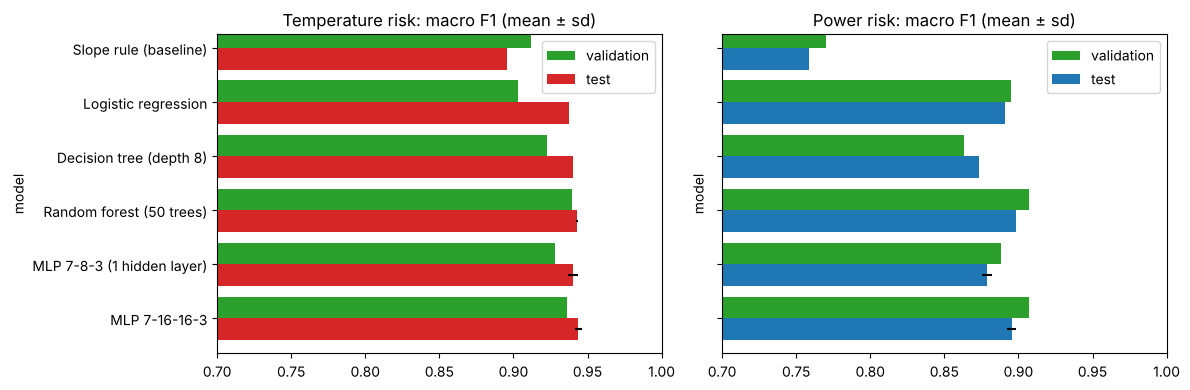

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
comp["val_temp_f1"].plot.barh(ax=ax[0], color="tab:green", position=1, width=0.4, label="validation")
comp["temp_f1"].plot.barh(ax=ax[0], xerr=comp["temp_f1_sd"], color="tab:red", position=0, width=0.4, label="test")
comp["val_power_f1"].plot.barh(ax=ax[1], color="tab:green", position=1, width=0.4, label="validation")
comp["power_f1"].plot.barh(ax=ax[1], xerr=comp["power_f1_sd"], color="tab:blue", position=0, width=0.4, label="test")
ax[0].set_title("Temperature risk: macro F1 (mean ± sd)"); ax[1].set_title("Power risk: macro F1 (mean ± sd)")
for a in ax: a.set_xlim(0.7, 1.0); a.invert_yaxis(); a.legend(loc="upper right")
ax[1].set_yticklabels([])
fig.tight_layout()
print("Selected by the validation rule:", comp.index[comp["selected"] == 1][0])

**Choice: MLP 7-16-16-3** (502 parameters, about 2 KB), picked by the validation rule above, not by the test numbers. It is also supported by X-CUBE-AI through the `.tflite` export.
Honest note: on the test set logistic regression and the decision tree are within about 1 % F1. The clear result is *learned models beat the hand rule*; among the learned models the MLP is the one validation points to, and the random forest (about 350 KB) does not fit the MCU.

## 6. Train the chosen model and export it

`train_model.py` trains the MLP (Adam, learning rate 0.003, batch 64, class-balanced weights, early stopping on a 15 % validation split). It trains **5 seeds and keeps the one with the lowest validation loss**; the choice never looks at the test set and writes:
- `Core/Inc/model_weights.h`: weights + scaler + limits, used by the plain C engine in `predictor.c`
- `model_out/model.tflite`: the input for X-CUBE-AI
- `model_out/report.md`, `metrics.json`, `history.json`, `prediction_example.png`

Loading data
  ../data/auto1.csv: 10800 rows
Observed: max rise ~11.1 C, power 68-235 mW
Thresholds: {'caution_rise': 5.5, 'critical_rise': 8.9, 'caution_power': 160.1, 'critical_power': 210.3}
Train rows 8082, test rows 2694
Train temp classes: [2513 1802 3767]  power classes: [3075 1372 3635]


seed 42: best validation loss 0.6571 after 42 epochs


seed 43: best validation loss 0.6303 after 62 epochs


seed 44: best validation loss 0.5872 after 78 epochs


seed 45: best validation loss 0.6550 after 38 epochs


...

INFO:tensorflow:Assets written to: /tmp/tmp0cy39il5/assets


INFO:tensorflow:Assets written to: /tmp/tmp0cy39il5/assets


Saved artifact at '/tmp/tmp0cy39il5'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 7), dtype=tf.float32, name='features')
Output Type:
  List[TensorSpec(shape=(None, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)]
Captures:
  139833675866832: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139833675871632: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139833675864912: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139833675873360: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139833675860496: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139833675864720: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139833675860112: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139833675869712: TensorSpec(shape=(), dtype=tf.resource, name=None)


W0000 00:00:1793017441.711936   22285 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1793017441.712017   22285 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1793017441.712989   22285 reader.cc:83] Reading SavedModel from: /tmp/tmp0cy39il5
I0000 00:00:1793017441.714167   22285 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1793017441.714195   22285 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmp0cy39il5
I0000 00:00:1793017441.720136   22285 mlir_graph_optimization_pass.cc:437] MLIR V1 optimization pass is not enabled
I0000 00:00:1793017441.721433   22285 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1793017441.773279   22285 loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmp0cy39il5
I0000 00:00:1793017441.781709   22285 loader.cc:471] SavedModel load for tags { serve }; Status: success: OK. Took 68737 microseconds.
I0000 00:00:1793017441.794396   22285

# Model report

Horizon H = 15 s, window = 10 s, features = temp_rise, temp_slope10, temp_slope3, power_now, power_avg10, power_slope10, workload.
Thresholds: caution +5.5 C / critical +8.9 C above idle baseline;
power caution 160.1 mW / critical 210.3 mW.
Train rows 8082, test rows 2694 (last 25 % of every recording segment).
Model: 502 parameters (~2.0 KB of float weights); seed 44 kept out of 5 by lowest validation loss.

## Temperature risk (test set)

| Predictor | Accuracy | Macro F1 | False alarm rate | Critical recall | Critical missed as Normal |
|---|---|---|---|---|---|
| ML model | 0.961 | 0.947 | 0.002 | 0.984 | 0.001 |
| Slope rule | 0.924 | 0.895 | 0.006 | 0.975 | 0.002 |

CRITICAL warning lead time before the limit was actually crossed (ideal is about H):
- ML model: mean 14.0 s, median 15.0 s over 8 crossings
- Slope rule: mean 20.0 s, median 19.5 s over 8 crossings

## Power risk (test set)

| Predictor | Accuracy | Macro F1 | False alarm rate | Critical recall | Crit

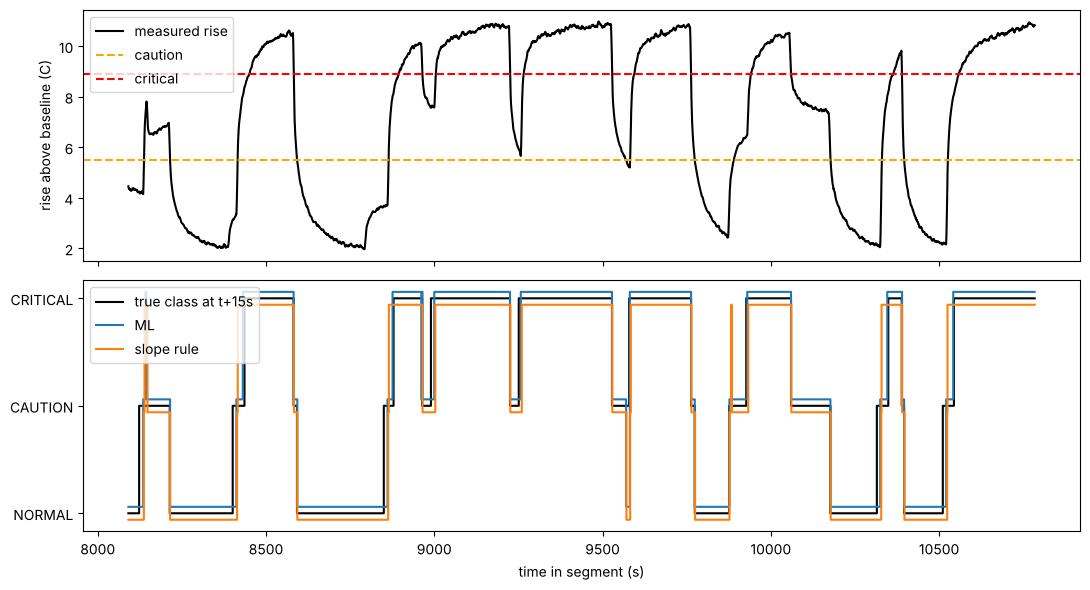

In [10]:
%run ../scripts/train_model.py --data ../data/auto1.csv

Text(0.5, 1.0, 'Training stopped after 78 epochs (early stopping kept the best)')

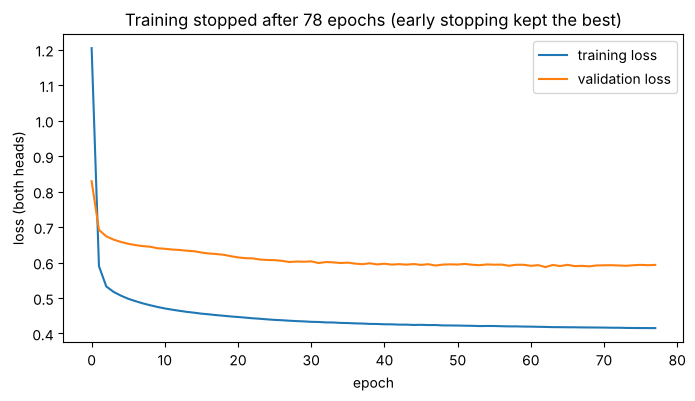

In [11]:
hist = json.loads((ROOT / "model_out" / "history.json").read_text())
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(hist["loss"], label="training loss"); ax.plot(hist["val_loss"], label="validation loss")
ax.set_xlabel("epoch"); ax.set_ylabel("loss (both heads)"); ax.legend()
ax.set_title(f"Training stopped after {len(hist['loss'])} epochs (early stopping kept the best)")

## 7. Results on the unseen test data: ML vs the slope rule

In [12]:
m = json.loads((ROOT / "model_out" / "metrics.json").read_text())
rows = []
for head in ["temp", "power"]:
    for who in ["ml", "rule"]:
        r = m["results"][head][who]
        rows.append({"risk": head, "predictor": "ML (MLP)" if who == "ml" else "slope rule",
                     "accuracy": r["accuracy"], "macro F1": r["macro_f1"],
                     "false alarm rate": r["false_alarm_rate"], "critical recall": r["critical_recall"]})
pd.DataFrame(rows).set_index(["risk", "predictor"]).round(3)

accuracy  macro F1  false alarm rate  critical recall
risk  predictor                                                        
temp  ML (MLP)       0.961     0.947             0.002            0.984
      slope rule     0.924     0.895             0.006            0.975
power ML (MLP)       0.934     0.895             0.059            0.984
      slope rule     0.877     0.759             0.071            0.978

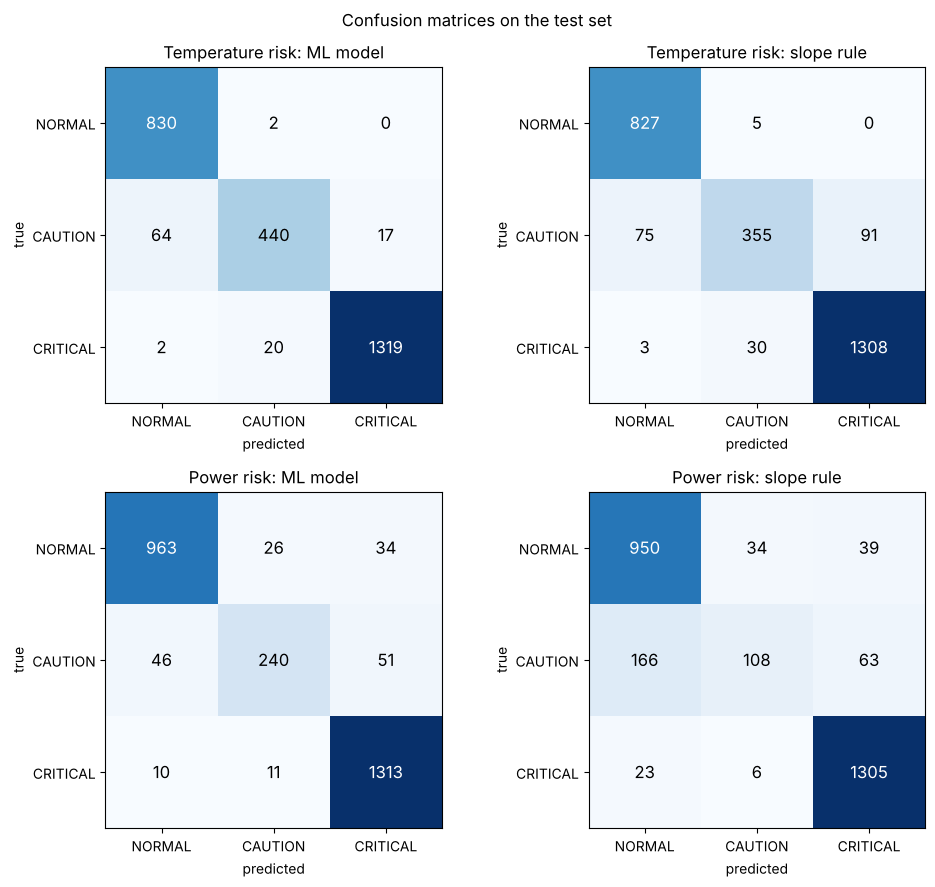

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(10, 9))
for ax_, (head, who) in zip(axes.ravel(), [("temp", "ml"), ("temp", "rule"), ("power", "ml"), ("power", "rule")]):
    cmx = np.array(m["results"][head][who]["confusion"])
    ax_.imshow(cmx, cmap="Blues")
    for a in range(3):
        for b in range(3):
            ax_.text(b, a, cmx[a, b], ha="center", va="center", fontsize=12,
                     color="white" if cmx[a, b] > cmx.max() / 2 else "black")
    ax_.set_xticks(range(3), tm.CLASS_NAMES); ax_.set_yticks(range(3), tm.CLASS_NAMES)
    ax_.set_title(f"{'Temperature' if head == 'temp' else 'Power'} risk: {'ML model' if who == 'ml' else 'slope rule'}")
    ax_.set_xlabel("predicted"); ax_.set_ylabel("true")
fig.suptitle("Confusion matrices on the test set")
fig.tight_layout()

Read the middle row (true CAUTION): the rule pushes many CAUTION cases up to CRITICAL (over-warning, which would throttle needlessly); the model keeps them as CAUTION.

In [14]:
print("CRITICAL warning lead time before the limit was crossed (ideal ≈ H = 15 s):")
for who in ["ml", "rule"]:
    v = m[f"lead_{who}"]
    print(f"  {who:4s}: mean {np.mean(v):.1f} s, median {np.median(v):.1f} s over {len(v)} crossings")

CRITICAL warning lead time before the limit was crossed (ideal ≈ H = 15 s):
  ml  : mean 14.0 s, median 15.0 s over 8 crossings
  rule: mean 20.0 s, median 19.5 s over 8 crossings


The rule warns earlier on average, but only because it calls CRITICAL too often (see the confusion matrices); the model's lead time is close to the 15 s it was trained for.

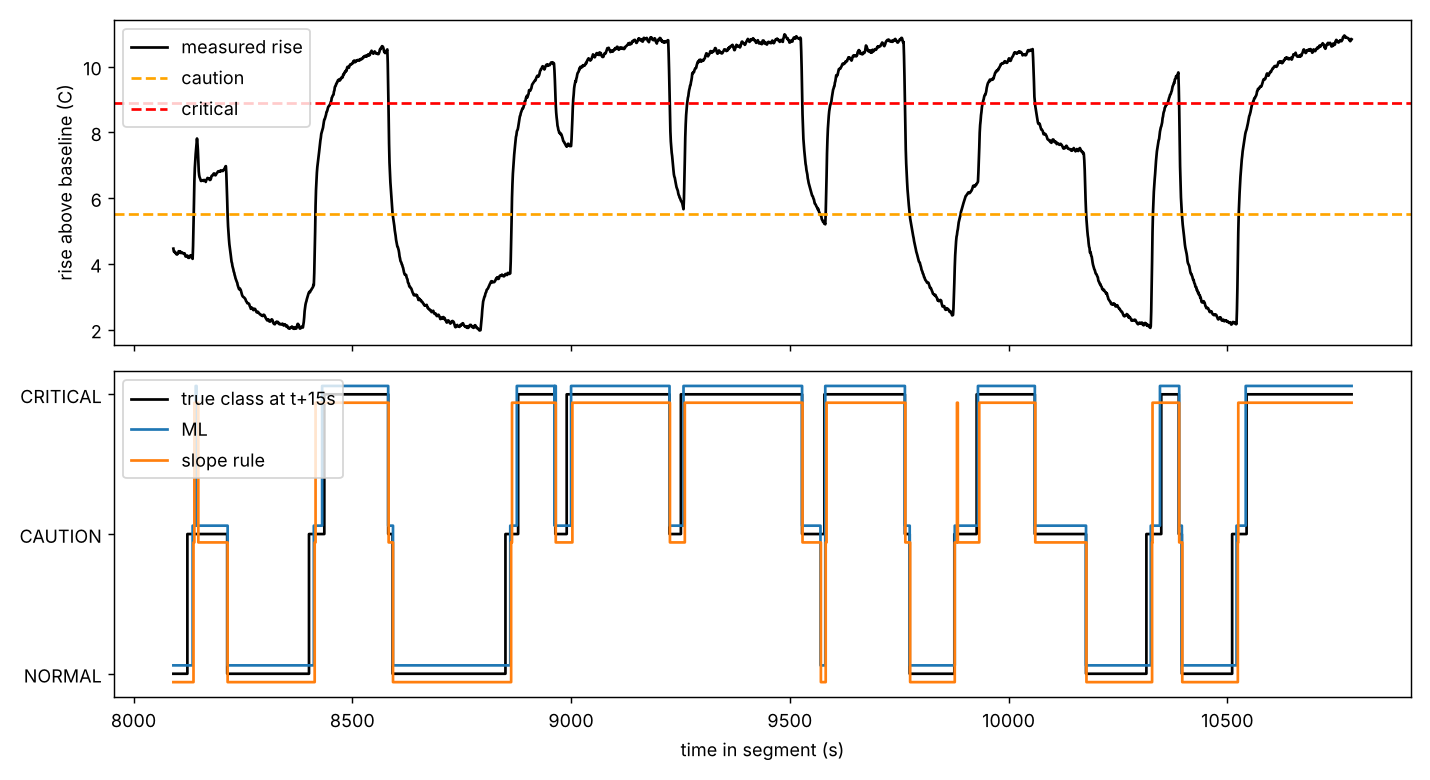

In [15]:
from IPython.display import Image
Image(str(ROOT / "model_out" / "prediction_example.png"))

## 8. On the MCU

- The C engine (`predictor.c`) gives the same class as Keras on 200 / 200 saved test vectors (`model_out/test_vectors.npz`).
- Inference time is measured on the board with the cycle counter and shown on the `[SYS]` line.
- With `INFERENCE_ENGINE_XCUBEAI 1` (see `docs/XCUBEAI.md`) the X-CUBE-AI engine runs from `model.tflite` next to the C engine, and both times are logged.

In [16]:
print(f"Model: {m['params']} parameters = {m['params'] * 4 / 1024:.1f} KB of float32 weights")
print(f"Train rows {m['train_rows']}, test rows {m['test_rows']}, thresholds {m['thresholds']}")

Model: 502 parameters = 2.0 KB of float32 weights
Train rows 8082, test rows 2694, thresholds {'caution_rise': 5.5, 'critical_rise': 8.9, 'caution_power': 160.1, 'critical_power': 210.3}
